# Task 1: LoRA fine-tuning (Qwen2.5-0.5B-Instruct -> strict JSON)
Turn on **GPU T4 x1/x2** (the script pins one GPU), then **Run All**. About 20 minutes.

Each run is its own process (clean VRAM numbers) and is **skipped if its results file already exists**, so after an interruption just Run All again.
Runs: r=16 x 3 seeds (+ base model, base with 6 examples), r=4 x 3 seeds, and a 1-epoch run.
At the end `report_tables.md` has every table with 95% confidence intervals. **Download the zip in the last cell before closing Kaggle.**

In [1]:
!pip uninstall -y -q torchao
!pip install -q transformers peft datasets accelerate matplotlib
import torch
print('PyTorch', torch.__version__, '| CUDA available:', torch.cuda.is_available())
!nvidia-smi --query-gpu=name,memory.total --format=csv

PyTorch 2.11.0+cu130 | CUDA available: True
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


In [2]:
%%writefile task1_lora.py
"""
Task 1: LoRA fine-tuning on Qwen2.5-0.5B-Instruct for text -> JSON {action, item, priority}.

Run each configuration in its own process so peak VRAM numbers stay clean:
    python task1_lora.py --r 16 --alpha 32 --seed 42 --eval_base     # also scores the base model
    python task1_lora.py --r 16 --alpha 32 --seed 1 / --seed 2       # seeds
    python task1_lora.py --r 4  --alpha 8  --seed 42 / 1 / 2         # rank ablation, 3 seeds
    python task1_lora.py --r 16 --alpha 32 --seed 42 --epochs 1      # epoch ablation
    python task1_lora.py --mem                                       # 7B memory working
A finished run is skipped automatically (resumable); add --force to redo it.
"""
import argparse
import json
import math
import os
import random
import re

# Force single GPU so Kaggle T4x2 doesn't trigger DataParallel and skew batch size/memory
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

ACTIONS = ["buy", "schedule", "email", "cancel", "review", "update", "book", "pay"]
ITEMS = [
    "groceries", "dentist appointment", "project report", "gym membership",
    "flight ticket", "server logs", "client contract", "laptop charger",
    "electricity bill", "team standup", "cloud invoice", "internship form",
]

TRAIN_PHRASES = {
    "high": ["high priority", "urgent", "ASAP", "immediately", "by tonight"],
    "medium": ["medium priority", "normal priority", "soon", "this week"],
    "low": ["low priority", "whenever possible", "no rush", "not urgent"],
}
TEST_ONLY_PHRASES = {
    "high": ["critical", "right now", "this can't wait"],
    "medium": ["moderate urgency", "in a few days"],
    "low": ["when free", "someday", "if there's time"],
}
# Synonym verbs appear in training only so the model learns canonical action mapping
SYNONYMS = {
    "buy": ["purchase", "order", "pick up"],
    "schedule": ["arrange", "organize", "plan"],
    "email": ["send an email about", "message them about"],
    "cancel": ["call off", "terminate"],
    "review": ["look over", "go through", "inspect"],
    "update": ["modify", "revise", "edit"],
    "book": ["reserve", "secure"],
    "pay": ["settle", "clear"],
}
EDGE_ONLY_WORDS = ["set up", "fix ", "grab", "check ", "drop an email", "plz", "gotta", "nothing crazy"]

TRAIN_TEMPLATES = [
    "Please {action} the {item}, {p_phrase}.",
    "I need to {action} {item} ({p_phrase}).",
    "Remind me to {action} {item}. It is {p_phrase}.",
    "Task: {action} {item} - {p_phrase}.",
    "Can you {action} the {item}? Make it {p_phrase}.",
    "{p_phrase}: {action} the {item}.",
    "Don't forget to {action} {item}, {p_phrase}.",
    "We should {action} the {item} - flag it {p_phrase}.",
    "Todo ({p_phrase}): {action} {item}.",
    "Would you {action} the {item}? Mark it as {p_phrase}.",
    "{action} {item}, please. Priority: {p_phrase}.",
    "Next on my list is to {action} the {item}; {p_phrase}.",
]
TEST_TEMPLATES = [
    "Hey, make sure we {action} the {item} ({p_phrase}).",
    "Could you {action} {item}? Treat as {p_phrase}.",
    "Need to {action} {item} — {p_phrase}.",
    "Quick note: {action} the {item}, {p_phrase}.",
    "Please handle this {p_phrase}: {action} {item}.",
]

SYSTEM_PROMPT = "Extract action, item, and priority as strict JSON."
SYSTEM_LONG = (
    'Extract the task as JSON with exactly the keys "action" (one of buy, schedule, email, cancel, '
    'review, update, book, pay), "item" (string) and "priority" (high, medium or low). '
    "Output only the JSON object."
)


def tag_of(a) -> str:
    return f"r{a.r}_s{a.seed}_e{a.epochs}"


def result_path(a) -> str:
    return f"task1_results_{tag_of(a)}.json"


def make_target(action: str, item: str, priority: str) -> str:
    return json.dumps({"action": action, "item": item, "priority": priority})


HARD_EDGE_CASES = [
    {"prompt": "Plz cancel my gym membership before they charge me tomorrow!!", "target": make_target("cancel", "gym membership", "high"), "edge": True},
    {"prompt": "Maybe review the server logs next month if you get time", "target": make_target("review", "server logs", "low"), "edge": True},
    {"prompt": "Gotta pay the electricity bill today or power gets cut", "target": make_target("pay", "electricity bill", "high"), "edge": True},
    {"prompt": "Drop an email about the client contract sometime this week", "target": make_target("email", "client contract", "medium"), "edge": True},
    {"prompt": "Need a new laptop charger, mine is dead right now", "target": make_target("buy", "laptop charger", "high"), "edge": True},
    {"prompt": "Set up the team standup for Thursday, nothing crazy", "target": make_target("schedule", "team standup", "medium"), "edge": True},
    {"prompt": "Check the cloud invoice whenever you're bored", "target": make_target("review", "cloud invoice", "low"), "edge": True},
    {"prompt": "Grab groceries on the way home tonight", "target": make_target("buy", "groceries", "high"), "edge": True},
    {"prompt": "Fix the internship form before the portal closes in 2 hours", "target": make_target("update", "internship form", "high"), "edge": True},
    {"prompt": "Book a flight ticket for next month's trip, no hurry", "target": make_target("book", "flight ticket", "low"), "edge": True},
]


def build_samples(templates, count, rng, is_test=False, syn_prob=0.0, banned=()):
    rows, seen = [], set(banned)
    while len(rows) < count:
        action = rng.choice(ACTIONS)
        item = rng.choice(ITEMS)
        priority = rng.choice(list(TRAIN_PHRASES))
        unseen = is_test and (rng.random() < 0.5)
        phrase = rng.choice((TEST_ONLY_PHRASES if unseen else TRAIN_PHRASES)[priority])
        verb = rng.choice(SYNONYMS[action]) if rng.random() < syn_prob else action
        prompt = rng.choice(templates).format(action=verb, item=item, p_phrase=phrase)
        if prompt in seen:
            continue
        seen.add(prompt)
        rows.append({"prompt": prompt, "unseen_phrase": unseen, "target": make_target(action, item, priority)})
    return rows


def make_data(n_train: int = 900):
    train = build_samples(TRAIN_TEMPLATES, n_train, random.Random(42), syn_prob=0.35)
    std_test = build_samples(TEST_TEMPLATES, 90, random.Random(123), is_test=True, banned={d["prompt"] for d in train})
    test = std_test + HARD_EDGE_CASES

    # Guard against train/test leakage
    train_lower = [d["prompt"].lower() for d in train]
    unseen_phrases = [p for vals in TEST_ONLY_PHRASES.values() for p in vals]
    assert not ({d["prompt"] for d in train} & {d["prompt"] for d in test}), "Train/test prompt overlap"
    assert not any(p.lower() in t for p in unseen_phrases for t in train_lower), "Test phrase leaked into train"
    assert not any(w in t for w in EDGE_ONLY_WORDS for t in train_lower), "Edge wording leaked into train"
    return train, test


def parse_strict(text: str):
    try:
        obj = json.loads(text.strip())
    except Exception:
        return None
    return obj if isinstance(obj, dict) else None


def parse_lenient(text: str):
    cleaned = re.sub(r"```(?:json)?", "", text)
    match = re.search(r"\{.*?\}", cleaned, re.S)
    return parse_strict(match.group(0)) if match else None


def group_of(sample: dict) -> str:
    if sample.get("edge"):
        return "edge"
    return "std_unseen_phrase" if sample["unseen_phrase"] else "std_seen_phrase"


def score(name: str, outs: list[str], test: list[dict]) -> dict:
    report = {}
    for grp in ["std_seen_phrase", "std_unseen_phrase", "edge"]:
        idx = [i for i, d in enumerate(test) if group_of(d) == grp]
        gold = {i: json.loads(test[i]["target"]) for i in idx}
        res = {
            "n": len(idx),
            "strict_valid": sum(parse_strict(outs[i]) is not None for i in idx),
            "strict_exact": sum(parse_strict(outs[i]) == gold[i] for i in idx),
            "lenient_exact": sum(parse_lenient(outs[i]) == gold[i] for i in idx),
        }
        for key in ["action", "item", "priority"]:
            res[f"{key}_acc"] = sum((parse_lenient(outs[i]) or {}).get(key) == gold[i][key] for i in idx)
        report[grp] = res
        print(
            f"{name:20s} {grp:18s} n={res['n']:2d} valid={res['strict_valid']:2d} "
            f"exact(strict)={res['strict_exact']:2d} exact(lenient)={res['lenient_exact']:2d} | "
            f"action={res['action_acc']} item={res['item_acc']} priority={res['priority_acc']}"
        )

    failures = [
        {"prompt": d["prompt"], "group": group_of(d), "expected": d["target"], "got": outs[i]}
        for i, d in enumerate(test)
        if parse_lenient(outs[i]) != json.loads(d["target"])
    ]
    return {"scores": report, "failures": failures}


def mem_7b(layers: int = 32, d: int = 4096, ff: int = 11008, r: int = 16, params: float = 7e9) -> dict:
    """Back-of-envelope GPU memory for a 7B model (LLaMA-style dims). Activations are excluded."""
    gb = 1e9
    per_layer_attn = 4 * r * (d + d)        # q,k,v,o: each LoRA pair has r*(d_in + d_out) params
    per_layer_mlp = 3 * r * (d + ff)        # gate, up, down projections
    lora_params = layers * (per_layer_attn + per_layer_mlp)
    lora_state_gb = lora_params * 16 / gb   # fp32 weight 4B + grad 4B + Adam m 4B + Adam v 4B = 16 B/param
    quant_const_gb = params * 0.5 / 8 / gb  # NF4, block size 64, fp32 absmax: 32/64 = 0.5 bit per weight
    full_gb, lora_gb = params * 16 / gb, params * 2 / gb + lora_state_gb
    qlora_gb = params * 0.5 / gb + quant_const_gb + lora_state_gb
    print("=== 7B memory working (activations excluded) ===")
    print(f"Assumptions: {params/1e9:.0f}B params, {layers} layers, d={d}, MLP width={ff}, LoRA r={r} on all 7 linear layers, Adam optimizer.")
    print(f"LoRA params/layer = attention 4*{r}*({d}+{d}) = {per_layer_attn:,} + MLP 3*{r}*({d}+{ff}) = {per_layer_mlp:,}")
    print(f"LoRA params total = {layers} * {per_layer_attn + per_layer_mlp:,} = {lora_params/1e6:.1f}M ({lora_params / params * 100:.2f}% of 7B)")
    print(f"LoRA trainable state = {lora_params/1e6:.1f}M * 16 B = {lora_state_gb:.2f} GB")
    print(f"(a) Full FT : 7B * 16 B (fp16 weights 2 + fp16 grads 2 + fp32 master 4 + Adam m,v 8) = {full_gb:.1f} GB")
    print(f"(b) LoRA    : frozen fp16 base 7B * 2 B = {params*2/gb:.1f} GB + {lora_state_gb:.2f} GB = {lora_gb:.1f} GB")
    print(f"(c) QLoRA   : NF4 base 7B * 0.5 B = {params*0.5/gb:.1f} GB + quant constants {quant_const_gb:.2f} GB + {lora_state_gb:.2f} GB = {qlora_gb:.1f} GB")
    print("Activations (batch size, sequence length, gradient checkpointing) come on top and are not included.")
    return {"lora_params_M": round(lora_params / 1e6, 2), "full_ft_gb": round(full_gb, 2),
            "lora_gb": round(lora_gb, 2), "qlora_gb": round(qlora_gb, 2)}


def run(args) -> None:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import torch
    from peft import LoraConfig, get_peft_model
    from transformers import AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments, set_seed

    if not torch.cuda.is_available():
        raise SystemExit("NO GPU DETECTED. Enable GPU T4 in notebook settings and re-run.")

    model_id = "Qwen/Qwen2.5-0.5B-Instruct"
    train, test = make_data()
    for fname, rows in [("train.jsonl", train), ("test.jsonl", test)]:
        with open(fname, "w", encoding="utf-8") as f:
            for row in rows:
                f.write(json.dumps(row) + "\n")

    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token

    def encode(sample: dict) -> dict:
        prompt_txt = (
            f"<|im_start|>system\n{SYSTEM_PROMPT}<|im_end|>\n"
            f"<|im_start|>user\n{sample['prompt']}<|im_end|>\n"
            "<|im_start|>assistant\n"
        )
        ans_txt = f"{sample['target']}<|im_end|>"
        p_ids = tok(prompt_txt, add_special_tokens=False)["input_ids"]
        a_ids = tok(ans_txt, add_special_tokens=False)["input_ids"]
        # Mask prompt tokens with -100 so cross-entropy loss trains only on JSON output
        return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}

    train_ds = [encode(d) for d in train]

    def collate(batch: list[dict]) -> dict:
        max_len = max(len(x["input_ids"]) for x in batch)
        pad = lambda key, val: torch.tensor([x[key] + [val] * (max_len - len(x[key])) for x in batch])
        mask = torch.tensor([[1] * len(x["input_ids"]) + [0] * (max_len - len(x["input_ids"])) for x in batch])
        return {"input_ids": pad("input_ids", tok.pad_token_id), "labels": pad("labels", -100), "attention_mask": mask}

    set_seed(args.seed)
    # Load in float16 on GPU for lower memory footprint while keeping LoRA params in fp32
    try:
        base_model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float16)
    except TypeError:
        base_model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16)

    lora_cfg = LoraConfig(
        r=args.r,
        lora_alpha=args.alpha,
        lora_dropout=0.05,
        bias="none",
        target_modules="all-linear",
        task_type="CAUSAL_LM",
    )
    model = get_peft_model(base_model, lora_cfg)
    model.print_trainable_parameters()
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    mem_before = torch.cuda.memory_allocated() / 1e9
    torch.cuda.reset_peak_memory_stats()

    steps = math.ceil(len(train_ds) / 16) * args.epochs
    train_args = TrainingArguments(
        output_dir="tmp",
        per_device_train_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=args.epochs,
        learning_rate=args.lr,
        lr_scheduler_type="cosine",
        warmup_steps=int(0.1 * steps),
        fp16=True,
        logging_steps=10,
        save_strategy="no",
        report_to="none",
        remove_unused_columns=False,
        seed=args.seed,
    )
    eff_batch = train_args.train_batch_size * train_args.gradient_accumulation_steps
    print(f"GPUs used: {train_args.n_gpu} | effective batch size: {eff_batch} | optimizer steps: {steps}")
    assert train_args.n_gpu == 1, "Expected 1 GPU so batch size and memory stay consistent."

    trainer = Trainer(model=model, args=train_args, train_dataset=train_ds, data_collator=collate)
    trainer.train()

    peak_gb = round(torch.cuda.max_memory_allocated() / 1e9, 2)
    peak_reserved_gb = round(torch.cuda.max_memory_reserved() / 1e9, 2)
    print(f"[r={args.r} seed={args.seed} epochs={args.epochs}] before: {mem_before:.2f} GB | peak allocated: {peak_gb} GB | peak reserved: {peak_reserved_gb} GB")

    tag = tag_of(args)
    model.save_pretrained(f"adapter_{tag}")

    loss_pts = [(x["step"], x["loss"]) for x in trainer.state.log_history if "loss" in x]
    loss_log = [[round(x["epoch"], 3), x["loss"]] for x in trainer.state.log_history if "loss" in x]
    plt.figure(figsize=(6, 3.5))
    plt.plot(*zip(*loss_pts), marker="o", ms=3)
    plt.grid(alpha=0.3)
    plt.xlabel("step")
    plt.ylabel("training loss")
    plt.title(f"r={args.r}, alpha={args.alpha}, seed={args.seed}")
    plt.savefig(f"loss_curve_{tag}.png", dpi=150, bbox_inches="tight")
    plt.close()

    def generate_batch(system: str, batch_size: int = 16, shots=()) -> list[str]:
        model.eval()
        outputs = []
        for i in range(0, len(test), batch_size):
            chunk = test[i : i + batch_size]
            chats = []
            for d in chunk:
                msgs = [{"role": "system", "content": system}]
                for shot_prompt, shot_target in shots:  # few-shot examples as earlier chat turns
                    msgs += [{"role": "user", "content": shot_prompt}, {"role": "assistant", "content": shot_target}]
                msgs.append({"role": "user", "content": d["prompt"]})
                chats.append(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))
            inputs = tok(chats, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
            with torch.no_grad():
                gen = model.generate(**inputs, max_new_tokens=60, do_sample=False, pad_token_id=tok.pad_token_id)
            outputs.extend(tok.batch_decode(gen[:, inputs["input_ids"].shape[1] :], skip_special_tokens=True))
        return outputs

    results = {
        "config": {
            "r": args.r,
            "alpha": args.alpha,
            "lr": args.lr,
            "epochs": args.epochs,
            "seed": args.seed,
            "targets": "all-linear",
            "trainable_params": trainable_params,
            "n_gpu": train_args.n_gpu,
            "effective_batch_size": eff_batch,
            "optimizer_steps": steps,
            "peak_gpu_gb": peak_gb,
            "peak_reserved_gb": peak_reserved_gb,
            "allocated_before_training_gb": round(mem_before, 2),
            "model_dtype": "float16 base + fp32 LoRA adapters, fp16 autocast",
            "loss_log": loss_log,
        }
    }

    if args.eval_base:
        by_priority = {p: [d for d in train if json.loads(d["target"])["priority"] == p][:2] for p in ("high", "medium", "low")}
        shots = [(by_priority[p][i]["prompt"], by_priority[p][i]["target"]) for i in range(2) for p in ("high", "medium", "low")]
        with model.disable_adapter():
            long_outs = generate_batch(SYSTEM_LONG)
            short_outs = generate_batch(SYSTEM_PROMPT)
            shot_outs = generate_batch(SYSTEM_LONG, shots=shots)  # 6 TRAIN examples in the prompt, no fine-tuning
        results["base_long"] = score("base (long prompt)", long_outs, test)
        results["base_short"] = score("base (short prompt)", short_outs, test)
        results["base_fewshot"] = score("base (6-shot)", shot_outs, test)

    results["finetuned"] = score(f"fine-tuned r={args.r}", generate_batch(SYSTEM_PROMPT), test)

    with open(result_path(args), "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2)
    print(f"Saved {result_path(args)} | total failures: {len(results['finetuned']['failures'])}")


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--r", type=int, default=16)
    parser.add_argument("--alpha", type=int, default=32)
    parser.add_argument("--lr", type=float, default=2e-4)
    parser.add_argument("--epochs", type=int, default=3)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--eval_base", action="store_true")
    parser.add_argument("--mem", action="store_true")
    parser.add_argument("--force", action="store_true", help="redo a run even if its results file exists")
    cli_args = parser.parse_args()
    if cli_args.mem:
        mem_7b()
    else:
        done = os.path.exists(result_path(cli_args)) and not cli_args.force
        if done and cli_args.eval_base:
            with open(result_path(cli_args), encoding="utf-8") as fh:
                done = "base_fewshot" in json.load(fh)  # need the base/few-shot scores too
        if done:
            print(f"SKIP: {result_path(cli_args)} already exists (use --force to redo).")
        else:
            run(cli_args)

Writing task1_lora.py


In [3]:
%%writefile task1_summary.py
"""Summarise task1_results_*.json into report-ready tables; also writes report_tables.md.
Every number comes from your own runs. Verdict sentences are generated from the numbers so they cannot overclaim."""
import collections
import contextlib
import glob
import io
import json
import math
import re
import sys

import task1_lora as T

OUT = []


def emit(line: str = "") -> None:
    print(line)
    OUT.append(line)


def wilson(k: int, n: int, z: float = 1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return max(0.0, c - h), min(1.0, c + h)


def fmt(k: int, n: int) -> str:
    lo, hi = wilson(k, n)
    return f"{k}/{n} ({lo * 100:.0f}-{hi * 100:.0f}%)"


files = sorted(glob.glob("task1_results_*.json"))
if not files:
    sys.exit("No task1_results_*.json found. Run the training cells first.")
runs = [json.load(open(f, encoding="utf-8")) for f in files]
STD = ("std_seen_phrase", "std_unseen_phrase")
S = lambda r: r["finetuned"]["scores"]
std_exact = lambda sc: sum(sc[g]["lenient_exact"] for g in STD)
cfgof = lambda r: r["config"]
epochs_of = lambda r: cfgof(r).get("epochs", 3)

main16 = [r for r in runs if cfgof(r)["r"] == 16 and epochs_of(r) == 3]
rank4 = [r for r in runs if cfgof(r)["r"] == 4 and epochs_of(r) == 3]
ep1 = [r for r in runs if cfgof(r)["r"] == 16 and epochs_of(r) == 1]
base_run = next((r for r in runs if "base_long" in r), None)

first = S(runs[0])
n_std = sum(first[g]["n"] for g in STD)
n_unseen, n_edge = first["std_unseen_phrase"]["n"], first["edge"]["n"]

emit("# Task 1 report tables (generated from my own runs)")
emit("")
emit("## Run checks")
warn = []
for r in runs:
    c = cfgof(r)
    if c.get("n_gpu", 1) != 1 or c.get("effective_batch_size", 16) != 16:
        warn.append(f"r={c['r']} s={c['seed']} e={epochs_of(r)}: n_gpu={c.get('n_gpu')} batch={c.get('effective_batch_size')}")
    if c.get("allocated_before_training_gb", 0) > 0.05:
        warn.append(f"r={c['r']} s={c['seed']}: {c['allocated_before_training_gb']} GB already allocated before training")
if len(main16) < 3:
    warn.append(f"only {len(main16)} seed(s) for r=16, 3 epochs")
if len(rank4) < 3:
    warn.append(f"only {len(rank4)} seed(s) for r=4, 3 epochs")
if not ep1:
    warn.append("no 1-epoch run found")
if base_run is None:
    warn.append("no --eval_base run found")
emit("OK (no warnings)" if not warn else "WARNINGS: " + "; ".join(warn))

emit("")
emit(f"## Table 1: base vs fine-tuned (exact match, with Wilson 95% CI; std={n_std}, unseen-phrase={n_unseen}, edge={n_edge})")
emit("| model | std exact | unseen-phrase exact | edge exact | strict-valid JSON (std) |")
emit("|---|---|---|---|---|")
if base_run:
    for key, label in (("base_long", "base, long prompt"), ("base_short", "base, short prompt"), ("base_fewshot", "base, long prompt + 6 examples")):
        if key in base_run:
            sc = base_run[key]["scores"]
            emit(f"| {label} | {fmt(std_exact(sc), n_std)} | {fmt(sc['std_unseen_phrase']['lenient_exact'], n_unseen)} | "
                 f"{fmt(sc['edge']['lenient_exact'], n_edge)} | {sum(sc[g]['strict_valid'] for g in STD)}/{n_std} |")
for r in sorted(runs, key=lambda r: (-cfgof(r)["r"], epochs_of(r) != 3, cfgof(r)["seed"])):
    c, sc = cfgof(r), S(r)
    emit(f"| fine-tuned r={c['r']} a={c['alpha']} seed={c['seed']} epochs={epochs_of(r)} | {fmt(std_exact(sc), n_std)} | "
         f"{fmt(sc['std_unseen_phrase']['lenient_exact'], n_unseen)} | {fmt(sc['edge']['lenient_exact'], n_edge)} | "
         f"{sum(sc[g]['strict_valid'] for g in STD)}/{n_std} |")
emit("")
emit("Note: base short-prompt outputs are often wrapped in code fences, so strict-valid is low; exact match uses a lenient parser that strips fences.")


def rng(rs, fn):
    v = [fn(S(r)) for r in rs]
    return (min(v), max(v), sum(v) / len(v)) if v else None


def verdict(name_a, a, name_b, b, unit):
    """a, b = (min, max, mean) tuples. Never claims a winner when ranges overlap."""
    if a is None or b is None:
        return "not enough runs to compare."
    if a[0] > b[1]:
        return f"{name_a} higher on every seed ({a[0]}-{a[1]} vs {b[0]}-{b[1]} {unit}), though with only a few seeds this is still indicative."
    if b[0] > a[1]:
        return f"{name_b} higher on every seed ({b[0]}-{b[1]} vs {a[0]}-{a[1]} {unit}), though with only a few seeds this is still indicative."
    return f"NOT conclusive: ranges overlap ({name_a} {a[0]}-{a[1]}, {name_b} {b[0]}-{b[1]} {unit})."


emit("")
emit("## Table 2: seed variation and rank comparison (3 epochs)")
emit("| config | seeds | std exact range (mean) | unseen-phrase range | edge range |")
emit("|---|---|---|---|---|")
for label, rs in (("r=16, alpha=32", main16), ("r=4, alpha=8", rank4)):
    if rs:
        a, b, c = rng(rs, std_exact), rng(rs, lambda s: s["std_unseen_phrase"]["lenient_exact"]), rng(rs, lambda s: s["edge"]["lenient_exact"])
        emit(f"| {label} | {len(rs)} | {a[0]}-{a[1]} ({a[2]:.1f})/{n_std} | {b[0]}-{b[1]}/{n_unseen} | {c[0]}-{c[1]}/{n_edge} |")
emit("")
emit("Rank verdict (std exact): " + verdict("r=16", rng(main16, std_exact), "r=4", rng(rank4, std_exact), f"of {n_std}"))
emit("Rank verdict (edge exact): " + verdict("r=16", rng(main16, lambda s: s["edge"]["lenient_exact"]), "r=4", rng(rank4, lambda s: s["edge"]["lenient_exact"]), f"of {n_edge}"))

emit("")
emit("## Table 3: epoch ablation (r=16, one seed each)")
base_seed = next((cfgof(r)["seed"] for r in ep1), None)
e3_same = next((r for r in main16 if cfgof(r)["seed"] == base_seed), None)
if ep1 and e3_same:
    e1 = ep1[0]
    d_std = std_exact(S(e3_same)) - std_exact(S(e1))
    spread = (rng(main16, std_exact)[1] - rng(main16, std_exact)[0]) if len(main16) > 1 else 0
    emit("| epochs | std exact | edge exact | train loss at ~epoch 1 | final train loss |")
    emit("|---|---|---|---|---|")
    for label, r in (("1", e1), ("3", e3_same)):
        log = cfgof(r).get("loss_log", [])
        last = log[-1][1] if log else None
        at1 = next((l for ep, l in log if ep >= 1.0), last)  # 1-epoch run: last logged loss is its end of epoch 1
        emit(f"| {label} | {fmt(std_exact(S(r)), n_std)} | {S(r)['edge']['lenient_exact']}/{n_edge} | "
             f"{'%.2e' % at1 if at1 is not None else 'n/a'} | {'%.2e' % last if last is not None else 'n/a'} |")
    emit("")
    emit("(The 1-epoch run uses its own complete learning-rate schedule, so its loss is not directly comparable with the 3-epoch run at the same point.)")
    close = abs(d_std) <= max(spread, 3)
    emit(f"Epoch verdict: 3 epochs minus 1 epoch = {d_std:+d} std-exact examples; seed-to-seed spread at 3 epochs is {spread}. "
         + ("Difference is within noise, so 3 epochs is probably more than needed (single seed, indicative only)." if close
            else "Difference exceeds seed noise (single seed, indicative only)."))
else:
    emit("(run the --epochs 1 config with the same seed as a 3-epoch run to fill this table)")

emit("")
emit("## Table 4: training config and VRAM (PyTorch counters, single GPU)")
emit("| r | alpha | seed | epochs | trainable params | batch | steps | peak allocated GB | peak reserved GB |")
emit("|---|---|---|---|---|---|---|---|---|")
for r in sorted(runs, key=lambda r: (-cfgof(r)["r"], epochs_of(r) != 3, cfgof(r)["seed"])):
    c = cfgof(r)
    emit(f"| {c['r']} | {c['alpha']} | {c['seed']} | {epochs_of(r)} | {c['trainable_params']:,} | {c['effective_batch_size']} | "
         f"{c['optimizer_steps']} | {c['peak_gpu_gb']} | {c.get('peak_reserved_gb', 'n/a')} |")
emit("")
emit("VRAM is torch.cuda.max_memory_allocated / max_memory_reserved. It excludes the CUDA context, so nvidia-smi will show more.")

emit("")
emit("## Priority confusion matrix on UNSEEN phrases (r=16, 3 epochs, all seeds pooled)")
_, test = T.make_data()
unseen_items = [d for d in test if not d.get("edge") and d["unseen_phrase"]]
true_count = collections.Counter(json.loads(d["target"])["priority"] for d in unseen_items)
conf = {t: collections.Counter() for t in ("high", "medium", "low")}
for r in main16:
    for t in true_count:
        conf[t][t] += true_count[t]  # start with everything on the diagonal, then move the errors off it
    for f in r["finetuned"]["failures"]:
        if f["group"] != "std_unseen_phrase":
            continue
        exp = json.loads(f["expected"])["priority"]
        got = (T.parse_lenient(f["got"]) or {}).get("priority", "other")
        if got != exp:
            conf[exp][exp] -= 1
            conf[exp][got if got in ("high", "medium", "low") else "other"] += 1
emit("| true \\ predicted | high | medium | low | other |")
emit("|---|---|---|---|---|")
for t in ("high", "medium", "low"):
    emit(f"| {t} (n={true_count[t] * len(main16)}) | " + " | ".join(str(conf[t][p]) for p in ("high", "medium", "low", "other")) + " |")
ext_errs = sum(conf[t][p] for t in ("high", "low") for p in ("high", "medium", "low", "other") if p != t)
to_med = sum(conf[t]["medium"] for t in ("high", "low"))
emit("")
if ext_errs:
    share = to_med / ext_errs
    emit(f"Of {ext_errs} errors on true high/low priorities (unseen phrases), {to_med} ({share:.0%}) were predicted as medium; "
         "chance would be about 50% because only two wrong labels exist. "
         + ("This supports the 'falls back to medium when the phrase is unfamiliar' hypothesis." if share >= 0.7
            else "This only weakly supports a fallback-to-medium pattern." if share >= 0.55
            else "This does NOT support a fallback-to-medium pattern; read the individual failures."))
else:
    emit("No errors on true high/low priorities for unseen phrases.")

emit("")
emit("## Priority errors by phrase (r=16, 3 epochs, all seeds pooled)")
phrases = sorted([(p, pr, "unseen") for pr, v in T.TEST_ONLY_PHRASES.items() for p in v]
                 + [(p, pr, "seen") for pr, v in T.TRAIN_PHRASES.items() for p in v], key=lambda x: -len(x[0]))
phrase_of = lambda prompt: next((p for p, _, _ in phrases if p.lower() in prompt.lower()), None)
trials, perrs = collections.Counter(), collections.Counter()
for d in test:
    if not d.get("edge"):
        trials[phrase_of(d["prompt"])] += len(main16)
for r in main16:
    for f in r["finetuned"]["failures"]:
        if f["group"] == "edge":
            continue
        if (T.parse_lenient(f["got"]) or {}).get("priority") != json.loads(f["expected"])["priority"]:
            perrs[phrase_of(f["prompt"])] += 1
emit("| phrase | seen/unseen | true priority | priority errors / trials |")
emit("|---|---|---|---|")
for p, pr, kind in sorted(phrases, key=lambda x: (x[2], x[1], x[0])):
    if trials[p]:
        emit(f"| {p} | {kind} | {pr} | {perrs[p]}/{trials[p]} |")

emit("")
emit("## Failures that happen on EVERY r=16 seed (pick 3 for the report)")
if main16:
    maps = [{f["prompt"]: f for f in r["finetuned"]["failures"]} for r in main16]
    common = sorted(set(maps[0]).intersection(*(set(m) for m in maps[1:])))
    for p in common:
        f = maps[0][p]
        emit(f"- [{f['group']}] {p}\n  expected: {f['expected']}\n  got:      {f['got']}")
    emit(f"({len(common)} consistent failures)")
    wrong = collections.Counter()
    for m in maps:
        for f in m.values():
            e, g = json.loads(f["expected"]), T.parse_lenient(f["got"]) or {}
            wrong.update(k for k in e if g.get(k) != e[k])
    emit("Wrong fields across all r=16 failures: " + json.dumps(dict(wrong)))

emit("")
emit("## 7B memory working")
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    T.mem_7b()
for line in buf.getvalue().splitlines():
    emit(line)

emit("")
emit("## Limitations to state in the report")
emit("- The data is synthetic and template-based, so high accuracy shows the model learned this format, not general language understanding.")
emit("- Unseen priority phrases are few (8 phrases), so phrase-level numbers are small samples; the edge set has only 10 hand-written examples.")
emit("- Some edge labels are subjective (for example 'nothing crazy' = medium), so a few edge failures may be label noise rather than model error.")
emit("- 3 seeds per config; differences smaller than the seed-to-seed range are not evidence.")
emit("- The test set was regenerated when the training data changed, so it is not comparable with earlier iterations.")

with open("report_tables.md", "w", encoding="utf-8") as fh:
    fh.write("\n".join(OUT) + "\n")
print("\nWrote report_tables.md")


Writing task1_summary.py


In [4]:
!python task1_lora.py --r 16 --alpha 32 --seed 42 --eval_base

config.json: 100%|█████████████████████████████| 659/659 [00:00<00:00, 2.29MB/s]
tokenizer_config.json: 100%|███████████████| 7.30k/7.30k [00:00<00:00, 17.0MB/s]
vocab.json: 100%|██████████████████████████| 2.78M/2.78M [00:00<00:00, 50.3MB/s]
merges.txt: 100%|███████████████████████████| 1.67M/1.67M [00:00<00:00, 119MB/s]
tokenizer.json: 100%|███████████████████████| 7.03M/7.03M [00:00<00:00, 156MB/s]

model.safetensors: downloading bytes: ▍                     | 20.9MB            
model.safetensors: downloading bytes: ██▍                   |  111MB, 5.72MB/s  
model.safetensors: downloading bytes: ███▌                  |  158MB, 10.9MB/s  
model.safetensors: downloading bytes: ████▋                 |  210MB, 15.3MB/s  
model.safetensors: downloading bytes: ██████████▍           |  469MB, 38.6MB/s  
model.safetensors: downloading bytes: ███████████▊          |  532MB, 44.1MB/s  
model.safetensors: reconstructing file:  48%|██▊   |  469MB /  988MB, 31.2MB/s  
model.safetensors: download

In [5]:
!python task1_lora.py --r 16 --alpha 32 --seed 1

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 626.40it/s]
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
GPUs used: 1 | effective batch size: 16 | optimizer steps: 171
{'loss': '0.4149', 'grad_norm': '1.475', 'learning_rate': '0.0001059', 'epoch': '0.177'}
{'loss': '0.07694', 'grad_norm': '0.4003', 'learning_rate': '0.0001999', 'epoch': '0.354'}
{'loss': '0.01697', 'grad_norm': '0.6443', 'learning_rate': '0.000197', 'epoch': '0.531'}
{'loss': '0.003942', 'grad_norm': '0.02225', 'learning_rate': '0.0001901', 'epoch': '0.708'}
{'loss': '0.0003663', 'grad_norm': '0.03165', 'learning_rate': '0.0001794', 'epoch': '0.885'}
{'loss': '0.0001688', 'grad_norm': '0.003972', 'learning_rate': '0.0001655', 'epoch': '1.053'}
{'loss': '0.0001314', 'grad_norm': '0.001923', 'learning_rate': '0.0001488', 'epoch': '1.23'}
{'loss': '9.729e-05', 'grad_norm': '0.0009282', 'learning_rate': '0.0001301', 'epoch': '1.407'}
{'loss': '8.915e-05', 'grad_norm': '0

In [6]:
!python task1_lora.py --r 16 --alpha 32 --seed 2

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 618.18it/s]
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
GPUs used: 1 | effective batch size: 16 | optimizer steps: 171
{'loss': '0.3909', 'grad_norm': '1.577', 'learning_rate': '0.0001059', 'epoch': '0.177'}
{'loss': '0.06374', 'grad_norm': '0.4218', 'learning_rate': '0.0001999', 'epoch': '0.354'}
{'loss': '0.01158', 'grad_norm': '0.1269', 'learning_rate': '0.000197', 'epoch': '0.531'}
{'loss': '0.003544', 'grad_norm': '0.01808', 'learning_rate': '0.0001901', 'epoch': '0.708'}
{'loss': '0.001127', 'grad_norm': '0.09915', 'learning_rate': '0.0001794', 'epoch': '0.885'}
{'loss': '0.0004789', 'grad_norm': '0.0395', 'learning_rate': '0.0001655', 'epoch': '1.053'}
{'loss': '0.0001455', 'grad_norm': '0.004695', 'learning_rate': '0.0001488', 'epoch': '1.23'}
{'loss': '0.0001234', 'grad_norm': '0.00151', 'learning_rate': '0.0001301', 'epoch': '1.407'}
{'loss': '0.0001331', 'grad_norm': '0.0023

In [7]:
!python task1_lora.py --r 4 --alpha 8 --seed 42

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 607.38it/s]
trainable params: 2,199,552 || all params: 496,232,320 || trainable%: 0.4433
GPUs used: 1 | effective batch size: 16 | optimizer steps: 171
{'loss': '0.5148', 'grad_norm': '1.23', 'learning_rate': '0.0001059', 'epoch': '0.177'}
{'loss': '0.1476', 'grad_norm': '0.8538', 'learning_rate': '0.0001999', 'epoch': '0.354'}
{'loss': '0.05853', 'grad_norm': '0.8142', 'learning_rate': '0.000197', 'epoch': '0.531'}
{'loss': '0.0214', 'grad_norm': '0.6968', 'learning_rate': '0.0001901', 'epoch': '0.708'}
{'loss': '0.007213', 'grad_norm': '0.2596', 'learning_rate': '0.0001794', 'epoch': '0.885'}
{'loss': '0.002133', 'grad_norm': '0.2147', 'learning_rate': '0.0001655', 'epoch': '1.053'}
{'loss': '0.001168', 'grad_norm': '0.05569', 'learning_rate': '0.0001488', 'epoch': '1.23'}
{'loss': '0.0004531', 'grad_norm': '0.0149', 'learning_rate': '0.0001301', 'epoch': '1.407'}
{'loss': '0.0003994', 'grad_norm': '0.009146', 'lear

In [8]:
!python task1_lora.py --r 4 --alpha 8 --seed 1

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 660.70it/s]
trainable params: 2,199,552 || all params: 496,232,320 || trainable%: 0.4433
GPUs used: 1 | effective batch size: 16 | optimizer steps: 171
{'loss': '0.5705', 'grad_norm': '1.534', 'learning_rate': '0.0001059', 'epoch': '0.177'}
{'loss': '0.1407', 'grad_norm': '0.7634', 'learning_rate': '0.0001999', 'epoch': '0.354'}
{'loss': '0.06167', 'grad_norm': '0.4617', 'learning_rate': '0.000197', 'epoch': '0.531'}
{'loss': '0.03235', 'grad_norm': '0.3023', 'learning_rate': '0.0001901', 'epoch': '0.708'}
{'loss': '0.009944', 'grad_norm': '0.357', 'learning_rate': '0.0001794', 'epoch': '0.885'}
{'loss': '0.002818', 'grad_norm': '0.02732', 'learning_rate': '0.0001655', 'epoch': '1.053'}
{'loss': '0.0009339', 'grad_norm': '0.01445', 'learning_rate': '0.0001488', 'epoch': '1.23'}
{'loss': '0.0006538', 'grad_norm': '0.0186', 'learning_rate': '0.0001301', 'epoch': '1.407'}
{'loss': '0.0005171', 'grad_norm': '0.03273', 'le

In [9]:
!python task1_lora.py --r 4 --alpha 8 --seed 2

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 668.50it/s]
trainable params: 2,199,552 || all params: 496,232,320 || trainable%: 0.4433
GPUs used: 1 | effective batch size: 16 | optimizer steps: 171
{'loss': '0.5394', 'grad_norm': '1.113', 'learning_rate': '0.0001059', 'epoch': '0.177'}
{'loss': '0.1359', 'grad_norm': '0.4689', 'learning_rate': '0.0001999', 'epoch': '0.354'}
{'loss': '0.05602', 'grad_norm': '0.8433', 'learning_rate': '0.000197', 'epoch': '0.531'}
{'loss': '0.02504', 'grad_norm': '0.2783', 'learning_rate': '0.0001901', 'epoch': '0.708'}
{'loss': '0.00609', 'grad_norm': '0.03345', 'learning_rate': '0.0001794', 'epoch': '0.885'}
{'loss': '0.002037', 'grad_norm': '0.5006', 'learning_rate': '0.0001655', 'epoch': '1.053'}
{'loss': '0.0008505', 'grad_norm': '0.01775', 'learning_rate': '0.0001488', 'epoch': '1.23'}
{'loss': '0.0006799', 'grad_norm': '0.02137', 'learning_rate': '0.0001301', 'epoch': '1.407'}
{'loss': '0.0004723', 'grad_norm': '0.03384', 'l

In [10]:
!python task1_lora.py --r 16 --alpha 32 --seed 42 --epochs 1

Loading weights: 100%|███████████████████████| 290/290 [00:00<00:00, 642.72it/s]
trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497
GPUs used: 1 | effective batch size: 16 | optimizer steps: 57
{'loss': '0.2855', 'grad_norm': '0.9694', 'learning_rate': '0.0001971', 'epoch': '0.177'}
{'loss': '0.02705', 'grad_norm': '0.5824', 'learning_rate': '0.0001663', 'epoch': '0.354'}
{'loss': '0.005915', 'grad_norm': '0.4367', 'learning_rate': '0.0001121', 'epoch': '0.531'}
{'loss': '0.0007165', 'grad_norm': '0.02912', 'learning_rate': '5.353e-05', 'epoch': '0.708'}
{'loss': '0.0004416', 'grad_norm': '0.01747', 'learning_rate': '1.145e-05', 'epoch': '0.885'}
{'train_runtime': '23.22', 'train_samples_per_second': '38.76', 'train_steps_per_second': '2.455', 'train_loss': '0.05611', 'epoch': '1'}
100%|███████████████████████████████████████████| 57/57 [00:23<00:00,  2.46it/s]
[r=16 seed=42 epochs=1] before: 0.00 GB | peak allocated: 2.98 GB | peak reserved: 6.67 GB
fine-tune

In [11]:
!python task1_lora.py --mem

=== 7B memory working (activations excluded) ===
Assumptions: 7B params, 32 layers, d=4096, MLP width=11008, LoRA r=16 on all 7 linear layers, Adam optimizer.
LoRA params/layer = attention 4*16*(4096+4096) = 524,288 + MLP 3*16*(4096+11008) = 724,992
LoRA params total = 32 * 1,249,280 = 40.0M (0.57% of 7B)
LoRA trainable state = 40.0M * 16 B = 0.64 GB
(a) Full FT : 7B * 16 B (fp16 weights 2 + fp16 grads 2 + fp32 master 4 + Adam m,v 8) = 112.0 GB
(b) LoRA    : frozen fp16 base 7B * 2 B = 14.0 GB + 0.64 GB = 14.6 GB
(c) QLoRA   : NF4 base 7B * 0.5 B = 3.5 GB + quant constants 0.44 GB + 0.64 GB = 4.6 GB
Activations (batch size, sequence length, gradient checkpointing) come on top and are not included.


## Report tables (generated from the runs above)

In [12]:
!python task1_summary.py

# Task 1 report tables (generated from my own runs)

## Run checks
OK (no warnings)

## Table 1: base vs fine-tuned (exact match, with Wilson 95% CI; std=90, unseen-phrase=49, edge=10)
| model | std exact | unseen-phrase exact | edge exact | strict-valid JSON (std) |
|---|---|---|---|---|
| base, long prompt | 35/90 (29-49%) | 18/49 (25-51%) | 2/10 (6-51%) | 62/90 |
| base, short prompt | 13/90 (9-23%) | 7/49 (7-27%) | 1/10 (2-40%) | 0/90 |
| base, long prompt + 6 examples | 49/90 (44-64%) | 25/49 (37-64%) | 2/10 (6-51%) | 90/90 |
| fine-tuned r=16 a=32 seed=1 epochs=3 | 78/90 (78-92%) | 37/49 (62-85%) | 4/10 (17-69%) | 90/90 |
| fine-tuned r=16 a=32 seed=2 epochs=3 | 74/90 (73-89%) | 33/49 (53-79%) | 3/10 (11-60%) | 90/90 |
| fine-tuned r=16 a=32 seed=42 epochs=3 | 77/90 (77-91%) | 36/49 (60-84%) | 5/10 (24-76%) | 90/90 |
| fine-tuned r=16 a=32 seed=42 epochs=1 | 81/90 (82-95%) | 41/49 (71-91%) | 7/10 (40-89%) | 90/90 |
| fine-tuned r=4 a=8 seed=1 epochs=3 | 72/90 (71-87%) | 32/49 (51

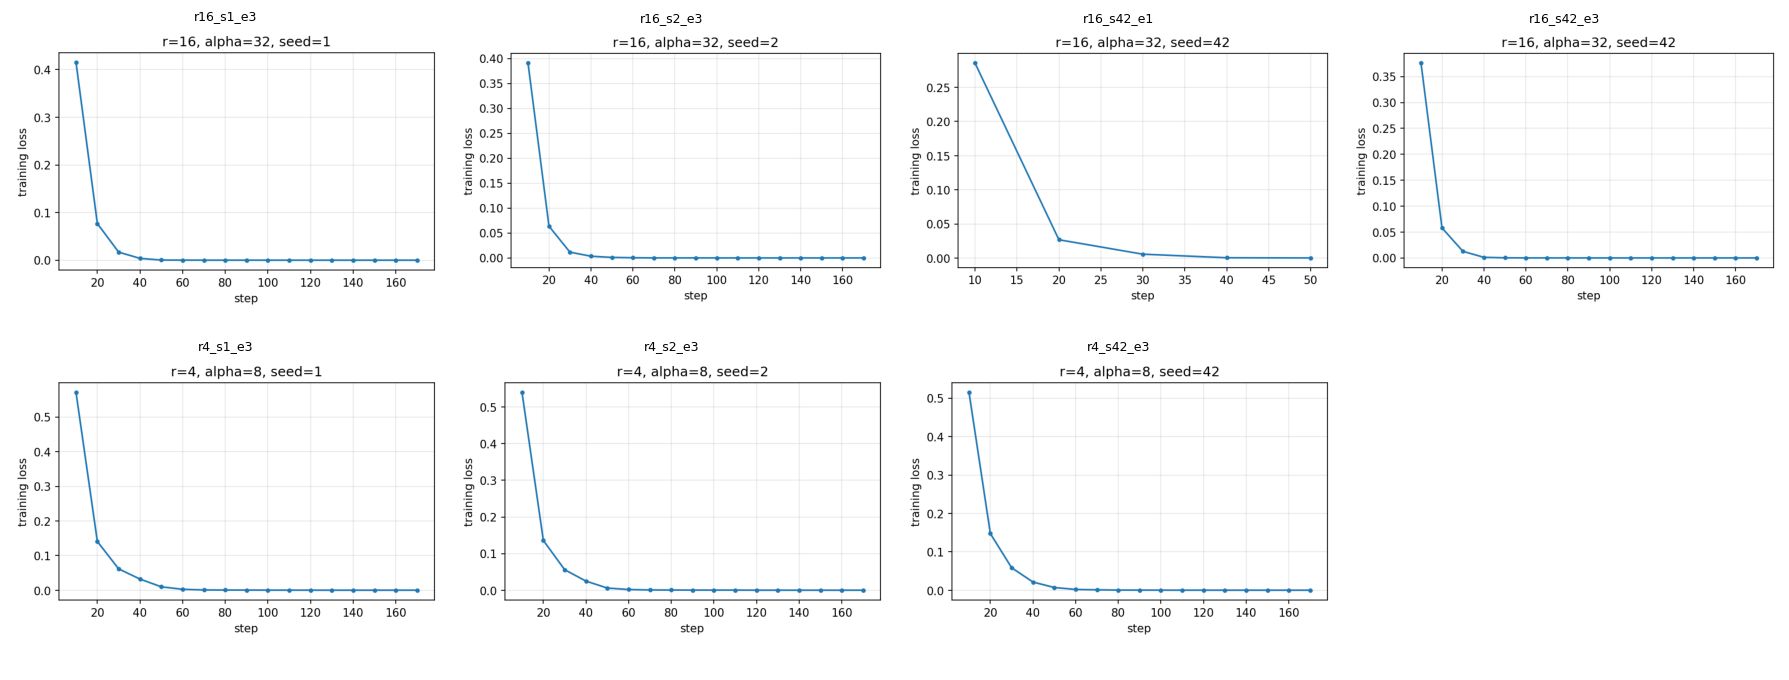

In [13]:
import glob
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

files = sorted(glob.glob('loss_curve_*.png'))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax in axes.ravel():
    ax.axis('off')
for ax, f in zip(axes.ravel(), files):
    ax.imshow(mpimg.imread(f)); ax.set_title(f.replace('loss_curve_', '').replace('.png', ''), fontsize=9)
plt.tight_layout(); plt.show()

## Download everything (Kaggle can lose files when the session ends)

In [14]:
!zip -q task1_outputs.zip task1_results_*.json loss_curve_*.png train.jsonl test.jsonl report_tables.md task1_lora.py task1_summary.py
!ls -la task1_outputs.zip

-rw-r--r-- 1 root root 236045 Nov 22 04:33 task1_outputs.zip
